# Proyecto: Campeonato Mundial de F1 - 04. Clasificación de podio

### Maestria en Inteligencia Artificial Aplicada UCSM - UTPL

### Curso: Herramientas para Inteligencia Artificial

### Github:
https://github.com/vchirinosb/f1-championship

### Plataformas utilizadas:
- Jupyter Lab
- Kaggle (origen del dataset)
- MLflow

### Librerias utilizadas
- pandas==3.1.1
- numpy==2.5.5
- scikit-learn==1.9.1
- matplotlib==3.11.2
- bokeh==3.10.2
- playwright==1.65.2
- mlflow==3.18.0
- skops==0.16.0

Estimamos la probabilidad de que un piloto termine en el **podio** (entre los 3 primeros) usando solo información
disponible **antes** de la carrera: posición de salida, clasificación, campeonato y forma reciente. Comparamos tres
modelos contra una línea base basada en la posición de salida, con una partición temporal que simula predecir temporadas
futuras. El modelo elegido se registra en MLflow para que la API lo use.

## Preparación del entorno

El código compartido está en `src/f1`: `features` (lista de variables del modelo), `plots` (exportación de gráficos) y
`tracking` (registro en MLflow). Antes de ejecutar la sección de MLflow, el servidor debe estar iniciado (ver README).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bokeh.io import output_notebook
from bokeh.plotting import figure
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from f1 import features, plots, tracking
from f1.config import FINAL_DATA_DIR

import mlflow

In [3]:
plots.INTERACTIVE = False
output_notebook(hide_banner=True)
RANDOM_STATE = 42

## Lectura del dataset final

Usamos las carreras desde 1994, el primer año con datos de clasificación (`quali_position`).

In [4]:
final = pd.read_csv(FINAL_DATA_DIR / "f1_dataset_final.csv")
races = final[final["year"] >= 1994].reset_index(drop=True)
races.shape

(12270, 39)

## Variable objetivo (podio) y balance de clases

`is_podium` vale `True` cuando el piloto termina entre los 3 primeros. Como en cada carrera hay 3 podios para unos 20
pilotos, las clases están desbalanceadas.

In [5]:
races["is_podium"].value_counts(normalize=True).round(3)

is_podium
False    0.859
True     0.141
Name: proportion, dtype: float64

Desde 1994 hay 12 270 participaciones y solo el 14.1 % terminó en el podio. Un modelo que dijera siempre "no podio"
acertaría el 85.9 % de las veces sin servir para nada; por eso no usamos la exactitud (*accuracy*) sino métricas
centradas en la clase podio: ROC-AUC, PR-AUC, F1, recall y precisión.

## Variables pre-carrera

Las variables del modelo (`features.PODIUM_FEATURES`) se calcularon en el notebook 02 con `shift(1)`, así que solo usan
información anterior a la carrera:

* **grid**: posición de salida (0 = salida desde el pit lane).
* **quali_position**: posición en la clasificación.
* **driver_points_before** / **driver_rank_before**: puntos y puesto del piloto en el campeonato antes de la carrera.
* **driver_form**: posición final media del piloto en sus últimas 5 carreras.
* **driver_circuit_form**: posición final media del piloto en ese circuito en visitas anteriores.
* **constructor_form**: posición final media de la escudería en sus últimas 5 carreras.
* **driver_races_before**: experiencia del piloto (carreras anteriores).
* **round**: número de la carrera en la temporada.

La **era reglamentaria** no se usa: la era de efecto suelo (2022-2024) solo aparece en el conjunto de prueba, así que el
modelo nunca la vería al entrenar.

In [6]:
FEATURES = features.PODIUM_FEATURES
races[FEATURES].isna().mean().round(3)

grid                    0.000
quali_position          0.148
driver_points_before    0.000
driver_rank_before      0.087
driver_form             0.011
driver_circuit_form     0.232
constructor_form        0.005
driver_races_before     0.000
round                   0.000
dtype: float64

Los nulos tienen una explicación:

* **driver_circuit_form** (23.2 %): es la primera visita del piloto a ese circuito.
* **quali_position** (14.8 %): el dataset no tiene la clasificación completa de 1996 a 2002 (entre el 41 % y el 94 % de
  nulos según el año).
* **driver_rank_before** (8.7 %): es la primera carrera de la temporada, todavía no hay campeonato.
* **driver_form** (1.1 %) y **constructor_form** (0.5 %): es el debut del piloto o de la escudería.

## Partición temporal

Separamos por temporada, nunca al azar: se entrena con el pasado y se evalúa con temporadas posteriores, como se usaría
el modelo en la realidad.

| Conjunto | Temporadas | Uso |
|---|---|---|
| Entrenamiento | 1994-2018 | Ajustar los modelos |
| Validación | 2019-2021 | Elegir el modelo y el umbral |
| Prueba | 2022-2024 | Medir el resultado final, una sola vez |

In [7]:
train = races[races["year"] <= 2018]
valid = races[races["year"].between(2019, 2021)]
test = races[races["year"] >= 2022]

# Cada conjunto termina antes de que empiece el siguiente, así que ninguna
# carrera aparece en dos conjuntos.
assert train["race_date"].max() < valid["race_date"].min()
assert valid["race_date"].max() < test["race_date"].min()

pd.DataFrame(
    [
        {
            "set": name,
            "rows": len(part),
            "races": part["race_id"].nunique(),
            "podium_share": round(part["is_podium"].mean(), 3)
        }
        for name, part in [("train", train), ("valid", valid),
                           ("test", test)]
    ]
).set_index("set")

,rows,races,podium_share
set,,,
train,9718,449,0.139
valid,1198,60,0.150
test,1354,68,0.151


In [8]:
X_train, y_train = train[FEATURES], train["is_podium"]
X_valid, y_valid = valid[FEATURES], valid["is_podium"]
X_test, y_test = test[FEATURES], test["is_podium"]

## Línea base

La línea base es la regla más simple: **"si sale entre los 3 primeros, sube al podio"**. Para calcular ROC-AUC y PR-AUC
también necesita un puntaje: usamos la posición de salida invertida (salir 1.° es el puntaje más alto) y la salida desde
el pit lane cuenta como la última posición.

Por ahora la evaluamos solo en validación: el conjunto de prueba se usa una sola vez, al final, para comparar la línea
base con el modelo elegido.

In [9]:
def compute_baseline_score(frame):
    """
    Calcular el puntaje de la línea base: mayor cuanto mejor la posición de
    salida.
    La clase de la línea base es podio cuando el puntaje es -3 o mayor, es
    decir, cuando el piloto sale entre los 3 primeros.

    :param frame: Filas con la columna grid.

    :return: Posición de salida con signo negativo; el pit lane es la 30.
    """
    return -frame["grid"].replace(0, 30)


def compute_metrics(y_true, score, predicted):
    """
    Calcular las métricas de la clase podio.

    :param y_true: Podio real.
    :param score: Probabilidad o puntaje de podio.
    :param predicted: Clase predicha.

    :return: Diccionario con roc_auc, pr_auc, f1, recall y precision.
    """
    return {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "f1": f1_score(y_true, predicted),
        "recall": recall_score(y_true, predicted),
        "precision": precision_score(y_true, predicted),
    }


pd.Series(
    compute_metrics(
        y_valid, compute_baseline_score(valid),
        compute_baseline_score(valid) >= -3
    )
).round(3)

roc_auc      0.917
pr_auc       0.677
f1           0.717
recall       0.717
precision    0.717
dtype: float64

La línea base es fuerte: en validación acierta el podio de 129 de los 180 pilotos que lo lograron (recall 0.717) con
F1 = 0.717, y su puntaje (la posición de salida) ya ordena muy bien a los pilotos (ROC-AUC 0.917, PR-AUC 0.677).
Superarla exige aprovechar la información que la posición de salida no tiene, como la forma reciente o el campeonato.

## Modelos

Comparamos tres modelos, 7 combinaciones en total: una regresión logística, cuatro Random Forest y dos
HistGradientBoosting. Todos usan `class_weight="balanced"`,
que da más peso a los podios para que el modelo no los ignore por ser pocos:

* **LogisticRegression**: modelo lineal; necesita imputar los nulos y estandarizar.
* **RandomForest**: muchos árboles de decisión entrenados con muestras distintas; necesita imputar los nulos.
* **HistGradientBoosting**: árboles que corrigen los errores de los anteriores; acepta nulos directamente.

`SimpleImputer(add_indicator=True)` reemplaza los nulos por la mediana y agrega una columna que indica si el valor
faltaba (por ejemplo, la primera visita a un circuito). Cada modelo es un `Pipeline` con su preprocesamiento.

In [10]:
def build_imputer():
    """
    Crear el imputador: reemplaza los nulos por la mediana y marca dónde
    faltaban.

    :return: SimpleImputer sin entrenar.
    """
    return SimpleImputer(strategy="median", add_indicator=True)


CANDIDATES = {
    "logistic": make_pipeline(
        build_imputer(), StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    )
}
for leaf in (20, 50):
    for max_features in ("sqrt", 0.5):
        CANDIDATES[f"random_forest_leaf{leaf}_{max_features}"] = make_pipeline(
            build_imputer(),
            RandomForestClassifier(
                n_estimators=300, min_samples_leaf=leaf,
                max_features=max_features, class_weight="balanced",
                n_jobs=-1, random_state=RANDOM_STATE,
            ),
        )

for depth in (3, None):
    CANDIDATES[f"hist_gradient_depth{depth}"] = make_pipeline(
        HistGradientBoostingClassifier(
            learning_rate=0.03, max_depth=depth, max_iter=300,
            class_weight="balanced", random_state=RANDOM_STATE,
        )
    )

len(CANDIDATES)

7

Entrenamos cada combinación con 1994-2018 y la comparamos en validación (2019-2021) por **PR-AUC**, el área bajo la
curva precisión-recall. Con clases desbalanceadas es más exigente que ROC-AUC, porque se fija en qué tan bien se
encuentran los pocos podios.

In [11]:
results = []
for name, pipeline in CANDIDATES.items():
    pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_valid)[:, 1]
    results.append(
        {
            "model": name,
            "roc_auc": roc_auc_score(y_valid, probability),
            "pr_auc": average_precision_score(y_valid, probability)
        }
    )

comparison = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
comparison.round(3)

,model,roc_auc,pr_auc
3,random_forest_leaf50_sqrt,0.938,0.736
4,random_forest_leaf50_0.5,0.936,0.733
1,random_forest_leaf20_sqrt,0.938,0.733
2,random_forest_leaf20_0.5,0.936,0.728
6,hist_gradient_depthNone,0.931,0.724
5,hist_gradient_depth3,0.938,0.721
0,logistic,0.928,0.711


Las cuatro mejores combinaciones son Random Forest. La mejor, con hojas de al menos 50 pilotos (`min_samples_leaf=50`)
y `max_features="sqrt"`, logra PR-AUC 0.736 en validación, frente a 0.677 de la línea base. Las hojas grandes evitan que
los árboles memoricen casos raros. HistGradientBoosting queda cerca (0.724 sin límite de profundidad). La regresión
logística (0.711) también supera a la línea base, pero no capta relaciones no lineales, como que salir 1.° vale mucho
más que salir 4.°.

## Umbral

Un modelo da una probabilidad; para decidir "podio" o "no podio" se necesita un umbral. El valor 0.5 no tiene por qué
ser el mejor: con `class_weight="balanced"` el modelo sobrestima la probabilidad de podio. Elegimos en validación el
umbral que maximiza el F1 de la clase podio.

In [12]:
best_name = comparison.iloc[0]["model"]
model = CANDIDATES[best_name]
valid_probability = model.predict_proba(X_valid)[:, 1]

thresholds = np.round(np.arange(0.10, 0.96, 0.01), 2)
f1_by_threshold = [
    f1_score(y_valid, valid_probability >= t) for t in thresholds
]
threshold = float(thresholds[int(np.argmax(f1_by_threshold))])
best_name, threshold, round(max(f1_by_threshold), 3)

('random_forest_leaf50_sqrt', 0.77, 0.732)

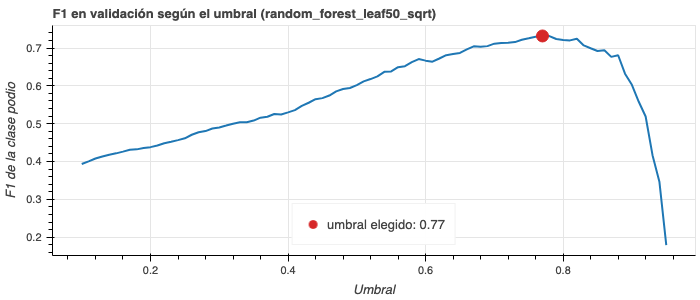

In [13]:
chart = figure(
    title=f"F1 en validación según el umbral ({best_name})",
    width=700, height=300
)
chart.line(thresholds, f1_by_threshold, line_width=2)
chart.scatter(
    [threshold], [max(f1_by_threshold)], size=12,
    color="#d62728", legend_label=f"umbral elegido: {threshold}"
)
chart.xaxis.axis_label = "Umbral"
chart.yaxis.axis_label = "F1 de la clase podio"
chart.legend.location = "bottom_center"
threshold_path = plots.render(chart, "podium_threshold")

El F1 en validación es máximo con un umbral de **0.77** (F1 = 0.732): con 0.5 el modelo marcaría como podio a demasiados
pilotos, porque `class_weight="balanced"` sube las probabilidades de la clase minoritaria. Por encima de 0.85 el F1 cae
rápido: el modelo solo marca podio a los casos más seguros y pierde muchos.

## Métricas y matriz de confusión

Evaluamos **una sola vez** en el conjunto de prueba (2022-2024) el modelo y el umbral elegidos en validación, y los
comparamos con la línea base.

In [14]:
test_probability = model.predict_proba(X_test)[:, 1]
test_predicted = test_probability >= threshold
test_metrics = compute_metrics(y_test, test_probability, test_predicted)
baseline_metrics = compute_metrics(
    y_test, compute_baseline_score(test),
    compute_baseline_score(test) >= -3
)
pd.DataFrame({"baseline": baseline_metrics, best_name: test_metrics}).T.round(3)

,roc_auc,pr_auc,f1,recall,precision
baseline,0.914,0.647,0.649,0.647,0.650
random_forest_leaf50_sqrt,0.938,0.716,0.677,0.721,0.639


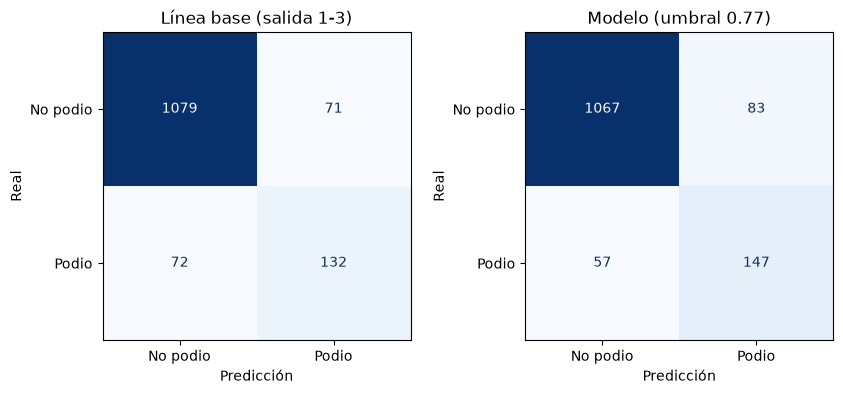

In [15]:
figure_cm, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, predicted, title in [
    (axes[0], compute_baseline_score(test) >= -3, "Línea base (salida 1-3)"),
    (axes[1], test_predicted, f"Modelo (umbral {threshold})"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, display_labels=["No podio", "Podio"], ax=ax,
        colorbar=False, cmap="Blues",
    )
    ax.set_title(title)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")

confusion_path = plots.render(figure_cm, "podium_confusion_matrix");

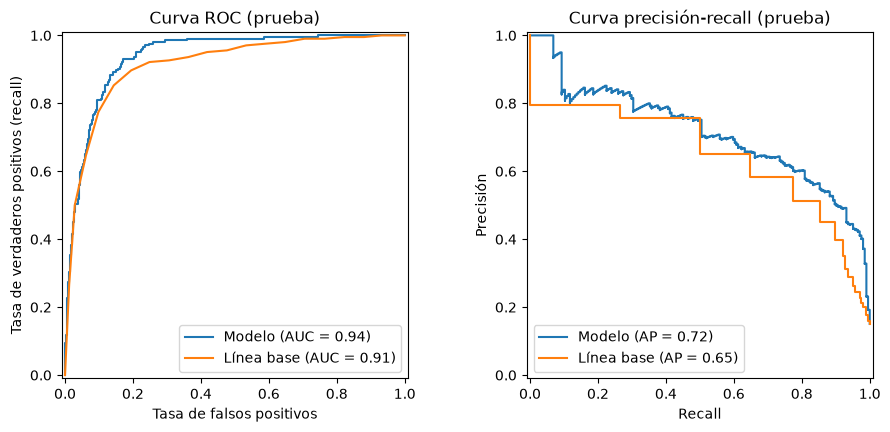

In [16]:
figure_curves, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for score, label in [
    (test_probability, "Modelo"),
    (compute_baseline_score(test), "Línea base")
]:
    RocCurveDisplay.from_predictions(y_test, score, name=label, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(
        y_test, score, name=label, ax=axes[1])

axes[0].set_title("Curva ROC (prueba)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos (recall)")
axes[1].set_title("Curva precisión-recall (prueba)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisión")
curves_path = plots.render(figure_curves, "podium_roc_pr");

En prueba (2022-2024, 68 carreras) el Random Forest con umbral 0.77 supera a la línea base en todas las métricas salvo
la precisión:

* **F1**: 0.677 frente a 0.649.
* **Recall**: encuentra 147 de los 204 podios (72.1 %), 15 más que la línea base.
* **Precisión**: 0.639 frente a 0.650; a cambio de esos aciertos marca 12 falsos podios más (83 frente a 71).
* **ROC-AUC** 0.938 y **PR-AUC** 0.716, frente a 0.914 y 0.647: ordena mejor a los pilotos por su probabilidad de podio.

La mejora es moderada porque la posición de salida ya explica la mayor parte del resultado; el modelo agrega la forma
del piloto y de la escudería, y detecta pilotos que salen 4.° o 5.° con un coche rápido.

## Importancia de variables

Usamos la **importancia por permutación** en validación: se desordena una variable a la vez y se mide cuánto baja la
PR-AUC. Cuanto más baja, más depende el modelo de esa variable. Funciona igual para cualquier modelo.

In [17]:
importance = permutation_importance(
    model, X_valid, y_valid, scoring="average_precision", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1,
)
importances = pd.Series(importance.importances_mean, index=FEATURES)
importances = importances.sort_values()
importances.round(4)

driver_circuit_form    -0.0047
round                  -0.0014
driver_races_before    -0.0006
driver_points_before    0.0055
driver_form             0.0214
constructor_form        0.0312
driver_rank_before      0.0435
quali_position          0.0526
grid                    0.1545
dtype: float64

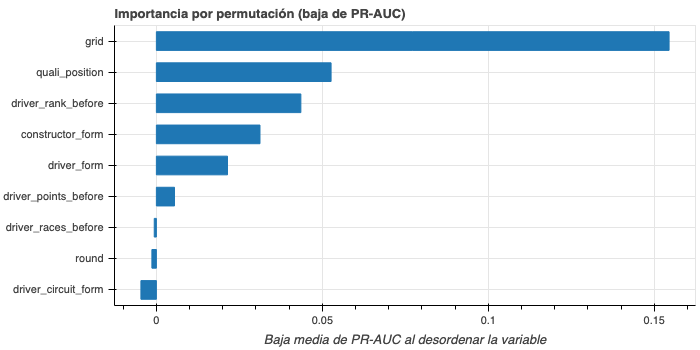

In [18]:
chart = figure(
    y_range=list(importances.index), width=700, height=350,
    title="Importancia por permutación (baja de PR-AUC)"
)
chart.hbar(y=list(importances.index), right=importances.values, height=0.6)
chart.xaxis.axis_label = "Baja media de PR-AUC al desordenar la variable"
importance_path = plots.render(chart, "podium_feature_importance");

**grid** es, por mucho, la variable más importante: al desordenarla la PR-AUC baja 0.155. Le siguen
**quali_position** (0.053), **driver_rank_before** (0.044), **constructor_form** (0.031) y **driver_form** (0.021):
la clasificación, el puesto en el campeonato y la forma reciente del coche y del piloto. **driver_circuit_form**,
**round** y **driver_races_before** no aportan (valores cercanos a 0 o negativos): el historial en un circuito, la
fecha de la temporada y la experiencia no ayudan una vez conocidas las demás variables.

## Predecir un caso nuevo

Una función recibe las variables pre-carrera de un piloto y devuelve la probabilidad de podio y la clase según el
umbral. Primero la aplicamos a todos los pilotos del **GP de Japón 2023**, una carrera del conjunto de prueba.

In [19]:
def predict_podium(rows, pipeline=model, cutoff=threshold):
    """
    Predecir la probabilidad de podio y la clase.

    :param rows: DataFrame o lista de diccionarios con las variables de
        FEATURES.
    :param pipeline: Clasificador; por defecto, el elegido aquí.
    :param cutoff: Umbral de la clase podio.

    :return: DataFrame con probability y podium.
    """
    probability = pipeline.predict_proba(pd.DataFrame(rows)[FEATURES])[:, 1]
    return pd.DataFrame(
        {"probability": probability.round(3), "podium": probability >= cutoff}
    )

In [20]:
japan = test[
    (test["year"] == 2023)
    & (test["race_name"] == "Japanese Grand Prix")
]
prediction = predict_podium(japan).set_index(japan.index)
japan[
    ["driver_name", "grid", "position_order"]
].join(prediction).sort_values("probability", ascending=False).head(8)

,driver_name,grid,position_order,probability,podium
11654,Max Verstappen,1,1,0.972,True
11655,Lando Norris,3,2,0.811,True
11672,Sergio Pérez,5,19,0.798,True
11657,Charles Leclerc,4,4,0.745,False
11656,Oscar Piastri,2,3,0.740,False
11659,Carlos Sainz,6,6,0.646,False
11658,Lewis Hamilton,7,5,0.580,False
11661,Fernando Alonso,10,8,0.432,False


En el GP de Japón 2023 el modelo da a Verstappen, que salió desde la pole, una probabilidad de 0.972, y acierta: ganó.
Norris (0.811), que salió 3.°, terminó 2.°. Pérez (0.798) estaba marcado como podio pero no terminó la carrera
(clasificado 19.°): los abandonos no se pueden prever con estas variables. Piastri, que salió 2.° en su primera
temporada,
terminó 3.° con una probabilidad de 0.740, justo debajo del umbral: su poca experiencia y su bajo puesto en el
campeonato pesan en contra. El caso hipotético (salida 2.°, segundo del campeonato, buena forma) recibe 0.932.

Un caso hipotético: un piloto que sale 2.°, va 2.° en el campeonato y viene de terminar en promedio 3.° en las últimas
carreras.

In [21]:
predict_podium(
    [
        {
            "grid": 2, "quali_position": 2, "driver_points_before": 180,
            "driver_rank_before": 2, "driver_form": 3.0,
            "driver_circuit_form": 4.0, "constructor_form": 3.5,
            "driver_races_before": 120, "round": 12
        }
    ]
)

,probability,podium
0,0.932,True


## Registro en MLflow

Igual que en el clustering, la comparación se registra como una ejecución padre con una ejecución hija por combinación
(con sus métricas de validación). En la ejecución padre se guardan el modelo elegido, el umbral, las métricas de prueba
del modelo y de la línea base, y los gráficos. El umbral y la lista de variables viajan como metadatos del modelo, para
que la API los use. Luego se registra como `f1-podium-classifier` con el alias `champion`.

In [22]:
with tracking.start_run(tracking.PODIUM_EXPERIMENT, "podium_models"):
    for row in comparison.itertuples():
        with tracking.start_run(run_name=row.model, nested=True):
            mlflow.log_params(CANDIDATES[row.model][-1].get_params())
            mlflow.log_metrics(
                {
                    "valid_roc_auc": row.roc_auc,
                    "valid_pr_auc": row.pr_auc
                }
            )

    mlflow.log_params(
        {
            "model": best_name, "threshold": threshold,
            "features": ", ".join(FEATURES), "train_years": "1994-2018",
            "valid_years": "2019-2021", "test_years": "2022-2024"
        }
    )
    mlflow.log_metrics(
        {f"test_{key}": value for key, value in test_metrics.items()}
    )
    mlflow.log_metrics(
        {f"baseline_test_{key}": value for key, value in baseline_metrics.items()}
    )
    for path in (
        threshold_path, confusion_path, curves_path, importance_path
    ):
        mlflow.log_artifact(path)

    info = tracking.log_model(
        model, X_train, {"threshold": threshold, "features": FEATURES}
    )
version = tracking.register_champion(info.model_uri, tracking.PODIUM_MODEL)
version

Registered model 'f1-podium-classifier' already exists. Creating a new version of this model...
Created version '2' of model 'f1-podium-classifier'.


2

**Verificación:** cargamos el modelo `champion` desde MLflow, como lo hará la API, con su umbral, y predecimos las
probabilidades del GP de Japón 2023 con la misma función `predict_podium`.

In [23]:
uri = f"models:/{tracking.PODIUM_MODEL}@{tracking.CHAMPION_ALIAS}"
champion = mlflow.sklearn.load_model(uri)
champion_threshold = mlflow.models.get_model_info(uri).metadata["threshold"]
loaded = predict_podium(japan, champion, champion_threshold)
assert loaded["probability"].between(0, 1).all()
assert (loaded.values == prediction.values).all()
loaded.set_index(japan.index).join(japan["driver_name"]).head(3)

,probability,podium,driver_name
11654,0.972,True,Max Verstappen
11655,0.811,True,Lando Norris
11656,0.740,False,Oscar Piastri


En el experimento `f1-podium` quedan la ejecución padre (`podium_models`) con las métricas de prueba del modelo y de
la línea base, y 7 ejecuciones hijas con la PR-AUC y la ROC-AUC de validación de cada combinación. El Random Forest
quedó registrado como una nueva versión de `f1-podium-classifier` (la 2 en esta ejecución) con el alias
`champion`. Cargado desde MLflow, con el umbral
leído de sus metadatos, devuelve las mismas probabilidades que el modelo del notebook.

## Conclusiones

- Usamos 12 270 participaciones desde 1994, con solo 14.1 % de podios, y nueve variables pre-carrera sin fuga de
  información. La era reglamentaria se descartó porque la era 2022-2024 solo aparece en prueba.
- La partición temporal (1994-2018, 2019-2021, 2022-2024) simula predecir temporadas futuras; un `assert` verifica que
  ninguna carrera está en dos conjuntos.
- Comparamos 7 combinaciones de regresión logística, Random Forest y HistGradientBoosting, con clases balanceadas.
  Ganó un Random Forest con hojas grandes (PR-AUC 0.736 en validación), con un umbral de 0.77 elegido en validación.
- En prueba supera a la línea base "sale entre los 3 primeros": F1 0.677 frente a 0.649, ROC-AUC 0.938 frente a 0.914 y
  15 podios más encontrados. La mejora es moderada porque la posición de salida es, por mucho, la variable más
  importante; los abandonos siguen siendo impredecibles.
- El modelo quedó registrado en MLflow como `f1-podium-classifier@champion`, con el umbral y las variables en sus
  metadatos, para que la API devuelva la probabilidad y la clase de podio.